In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from soja_clima.merge import carregar_base_final  # base única: base_final_modelagem.csv

PROCESSED_DIR = Path("../../data/processed")
df_soja = carregar_base_final(PROCESSED_DIR / "base_final_modelagem.csv")

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (14, 6)

print("Shape da base:", df_soja.shape)
print("\nEstatísticas Descritivas:")
print(df_soja[['quantidade_produzida', 'área_colhida', 'área_plantada', 'rendimento_recalculado']].describe().round(2))

print("\nAnos disponíveis:", df_soja['ano'].min(), "a", df_soja['ano'].max())
print(f"Total de microrregiões produtoras: {df_soja['CD_MICRO'].nunique()}")

Shape da base: (6998, 8)

Estatísticas Descritivas:
       quantidade_produzida  valor_da_producao  área_colhida  área_plantada  \
count               6993.00            6993.00       6993.00        6998.00   
mean               36781.85           46130.08      12312.45       12336.47   
std               107804.71          168337.18      33544.04       33611.33   
min                    1.00               0.00          1.00           0.00   
25%                  960.00             772.00        374.00         380.00   
50%                 5424.00            4823.00       2000.00        2000.00   
75%                28328.00           28164.00      10000.00       10000.00   
max              1754610.00         3792497.00     408000.00      408000.00   

       rendimento_recalculado  
count                 6993.00  
mean                  2793.64  
std                    732.02  
min                    105.56  
25%                   2400.00  
50%                   2895.94  
75%         

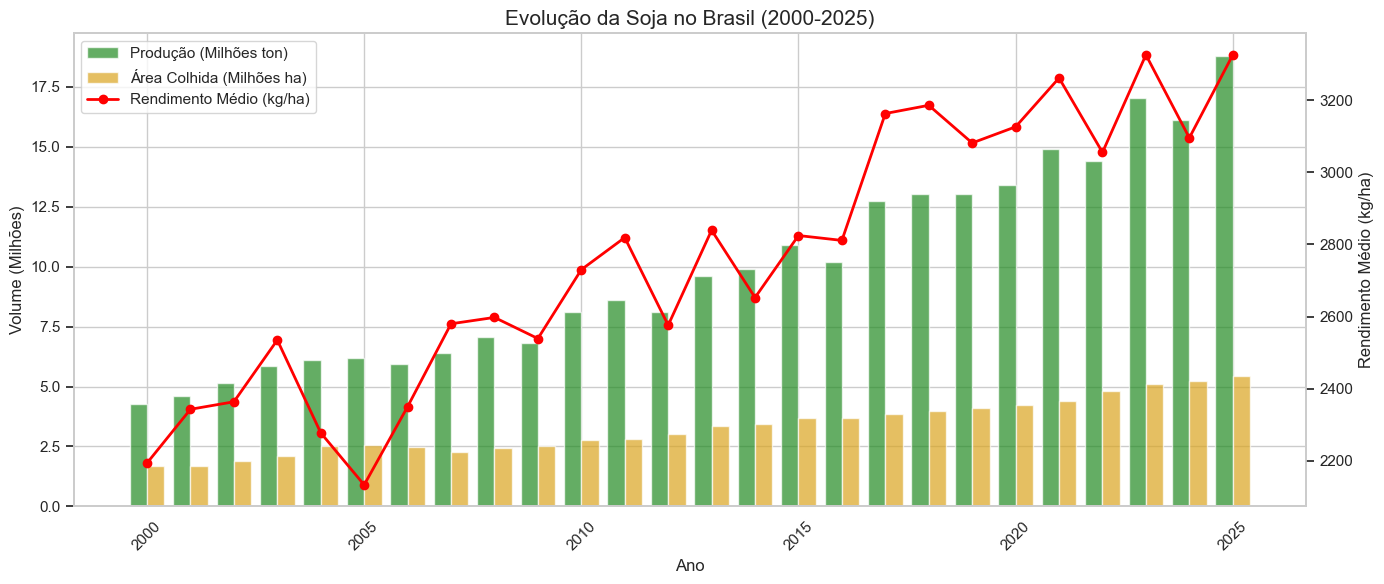

In [2]:
# Agrega os dados para o Brasil todo por ano
evolucao_anual = df_soja.groupby('ano').agg(
    producao_total=('quantidade_produzida', 'sum'),
    area_total=('área_colhida', 'sum'),
    rendimento_medio=('rendimento_recalculado', 'mean')
).reset_index()

fig, ax1 = plt.subplots(figsize=(14, 6))

# Eixo 1: Produção e Área
ax1.bar(evolucao_anual['ano'] - 0.2, evolucao_anual['producao_total'] / 1e6, width=0.4, color='forestgreen', label='Produção (Milhões ton)', alpha=0.7)
ax1.bar(evolucao_anual['ano'] + 0.2, evolucao_anual['area_total'] / 1e6, width=0.4, color='goldenrod', label='Área Colhida (Milhões ha)', alpha=0.7)
ax1.set_xlabel('Ano')
ax1.set_ylabel('Volume (Milhões)')
ax1.tick_params(axis='x', rotation=45)

# Eixo 2: Rendimento
ax2 = ax1.twinx()
ax2.plot(evolucao_anual['ano'], evolucao_anual['rendimento_medio'], color='red', marker='o', linewidth=2, label='Rendimento Médio (kg/ha)')
ax2.set_ylabel('Rendimento Médio (kg/ha)')
ax2.grid(False) # Desativa grade do segundo eixo

# Legenda unificada
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left')

plt.title(f"Evolução da Soja no Brasil ({evolucao_anual['ano'].min()}-{evolucao_anual['ano'].max()})", fontsize=15)
plt.tight_layout()
plt.show()

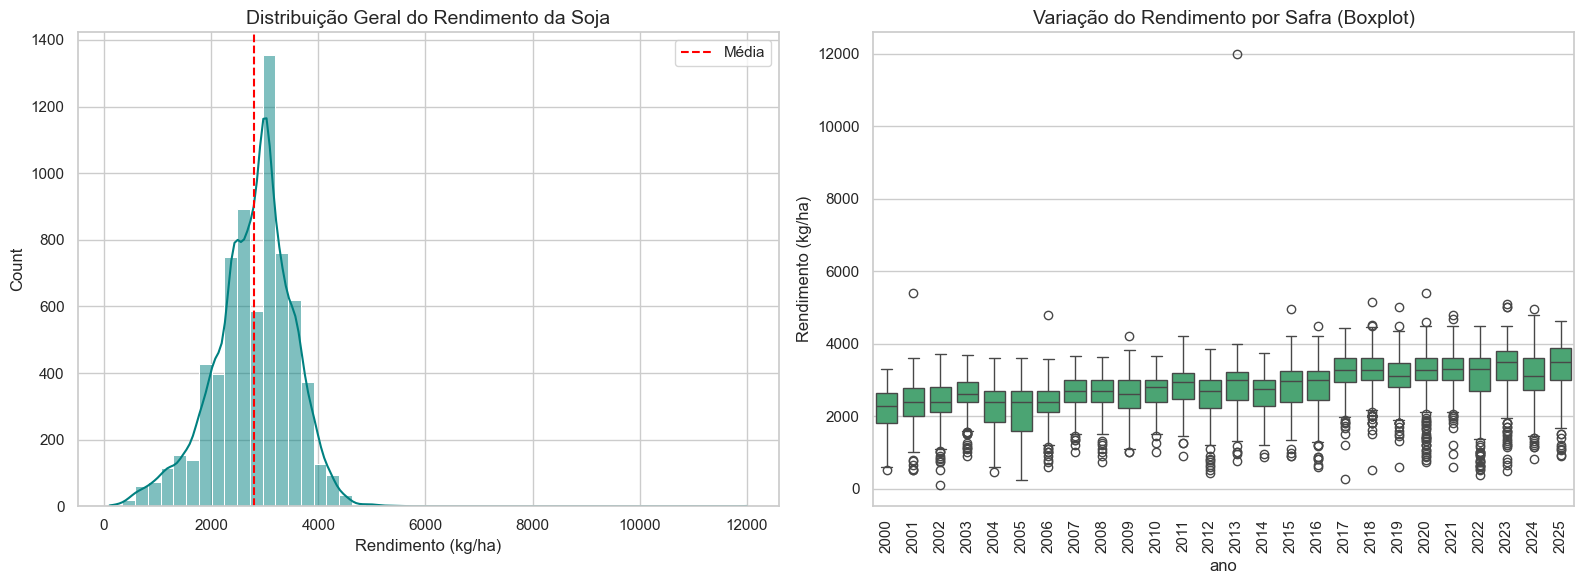

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Histograma Geral
sns.histplot(df_soja['rendimento_recalculado'].dropna(), bins=50, kde=True, ax=axes[0], color='teal')
axes[0].set_title('Distribuição Geral do Rendimento da Soja', fontsize=14)
axes[0].set_xlabel('Rendimento (kg/ha)')
axes[0].axvline(df_soja['rendimento_recalculado'].mean(), color='red', linestyle='--', label='Média')
axes[0].legend()

# 2. Boxplot por Ano (para ver a variação entre anos e quebras de safra)
sns.boxplot(data=df_soja, x='ano', y='rendimento_recalculado', ax=axes[1], color='mediumseagreen')
axes[1].set_title('Variação do Rendimento por Safra (Boxplot)', fontsize=14)
axes[1].set_ylabel('Rendimento (kg/ha)')
axes[1].tick_params(axis='x', rotation=90)

plt.tight_layout()
plt.show()

/var/folders/j3/kppygfjs7xj9nbzbwjj9cjc80000gn/T/ipykernel_73038/2303556456.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_volume.values / 1e6, y=top_volume.index, ax=axes[0], palette="viridis")
/var/folders/j3/kppygfjs7xj9nbzbwjj9cjc80000gn/T/ipykernel_73038/2303556456.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_rendimento.values, y=top_rendimento.index, ax=axes[1], palette="magma")


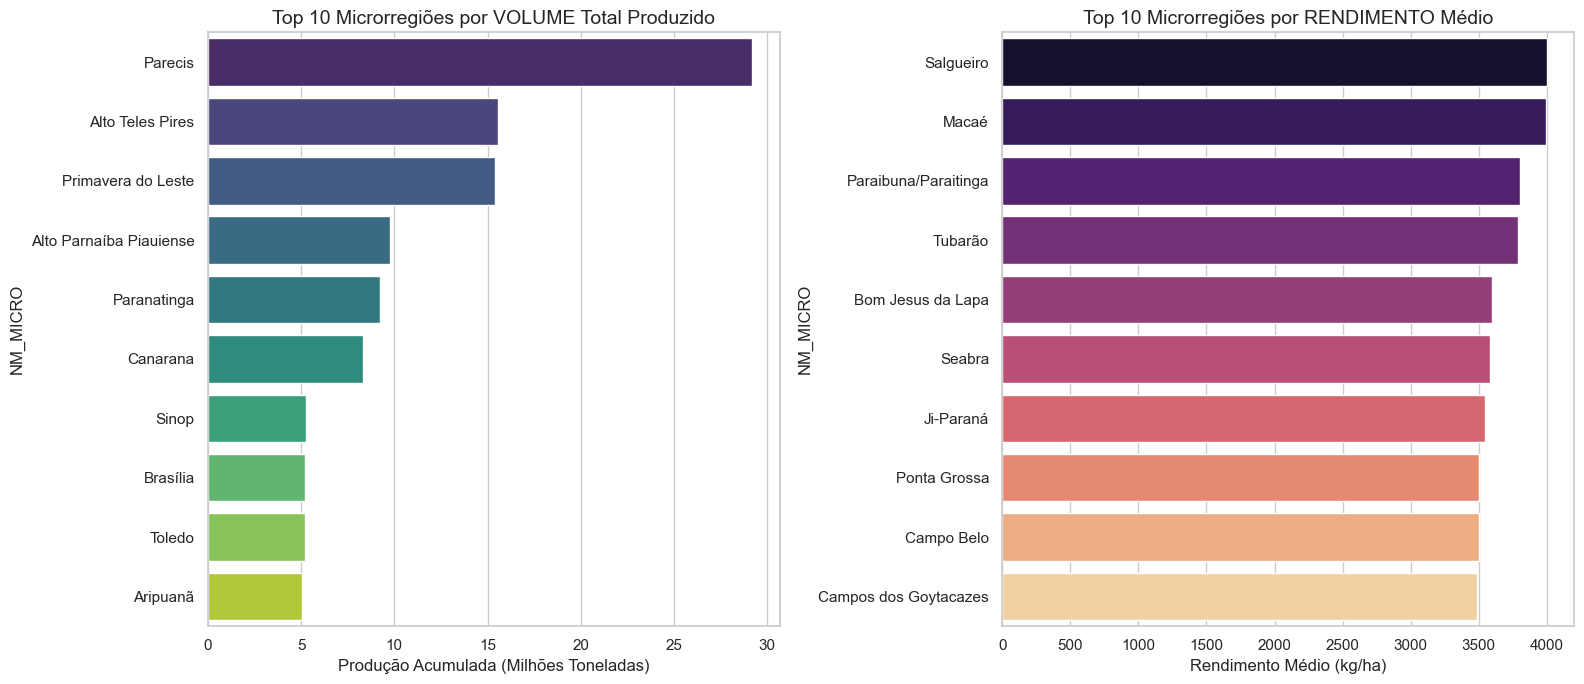

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# 1. Top 10 em Volume (Quantidade Produzida Total)
top_volume = df_soja.groupby('NM_MICRO')['quantidade_produzida'].sum().sort_values(ascending=False).head(10)
sns.barplot(x=top_volume.values / 1e6, y=top_volume.index, ax=axes[0], palette="viridis")
axes[0].set_title("Top 10 Microrregiões por VOLUME Total Produzido", fontsize=14)
axes[0].set_xlabel("Produção Acumulada (Milhões Toneladas)")

# 2. Top 10 em Eficiência (Rendimento Médio)
top_rendimento = df_soja.groupby('NM_MICRO')['rendimento_recalculado'].mean().sort_values(ascending=False).head(10)
sns.barplot(x=top_rendimento.values, y=top_rendimento.index, ax=axes[1], palette="magma")
axes[1].set_title("Top 10 Microrregiões por RENDIMENTO Médio", fontsize=14)
axes[1].set_xlabel("Rendimento Médio (kg/ha)")

plt.tight_layout()
plt.show()

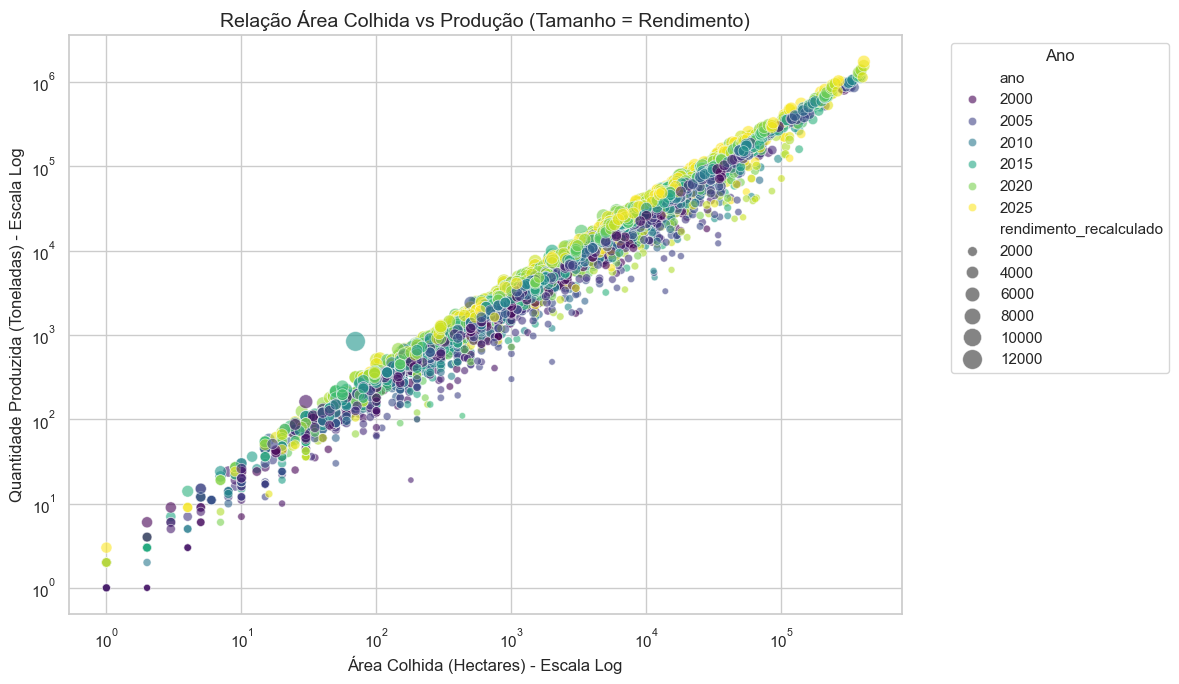

In [5]:
plt.figure(figsize=(12, 7))
sns.scatterplot(
    data=df_soja, 
    x='área_colhida', 
    y='quantidade_produzida', 
    hue='ano', 
    palette='viridis', 
    alpha=0.6,
    size='rendimento_recalculado',
    sizes=(20, 200)
)
plt.xscale('log') # Escala logarítmica porque há áreas de 10 ha e áreas de 500.000 ha
plt.yscale('log')
plt.title('Relação Área Colhida vs Produção (Tamanho = Rendimento)', fontsize=14)
plt.xlabel('Área Colhida (Hectares) - Escala Log')
plt.ylabel('Quantidade Produzida (Toneladas) - Escala Log')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', title='Ano')
plt.tight_layout()
plt.show()

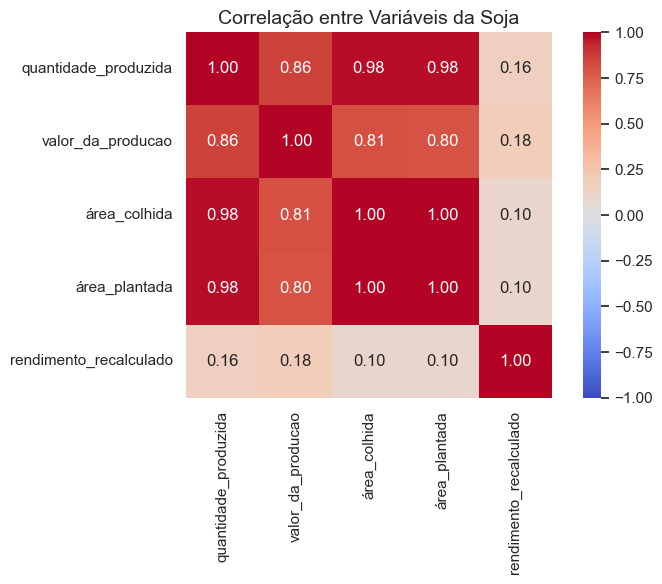

In [6]:
colunas_num = ['quantidade_produzida', 'área_colhida', 'área_plantada', 'rendimento_recalculado']
corr = df_soja[colunas_num].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap='coolwarm', vmin=-1, vmax=1, square=True)
plt.title('Correlação entre Variáveis da Soja', fontsize=14)
plt.tight_layout()
plt.show()